# Image Restoration: Theory and Practice

## Learning outcomes
By completing this module, students should be able to:
1. Distinguish image restoration from image enhancement.
2. Explain and simulate the blur-and-noise degradation model.
3. Characterize common noise distributions and estimate noise from homogeneous regions.
4. Select and implement mean, order-statistic, and adaptive noise-reduction filters.
5. Suppress periodic interference in the Fourier domain.
6. Explain the instability of inverse filtering and the role of Wiener regularization.
7. Assess restored images using quantitative fidelity metrics.

## Degradation and the inverse problem

An observed image is not necessarily an accurate representation of the underlying scene. Optical defocus, camera motion, imperfect imaging systems, and sensor noise can alter it. **Image restoration** estimates the latent image using assumptions about how degradation occurred; **image enhancement** may improve visual appearance without modeling the degradation.

For a spatially invariant linear blur and additive noise,

$$g(x,y) = (f*h)(x,y) + n(x,y),$$

where $f$ is the original image, $h$ is the **point spread function (PSF)**, $n$ is noise, and $g$ is the observed image. The Fourier convolution theorem gives

$$G(u,v)=F(u,v)H(u,v)+N(u,v).$$

Recovering $f$ from $g$ is an **inverse problem**. It may be ill-conditioned because blurring suppresses some frequency components, and noise may obscure them. In these exercises the PSF is known; real applications often require estimating it.

### Experiment 1 — Simulate image degradation
**Tasks:** Construct a normalized PSF, apply blur, add noise, and inspect the separate and combined effects.  
**Question:** Why is the blurred-and-noisy observation harder to restore than a blurred-only image?

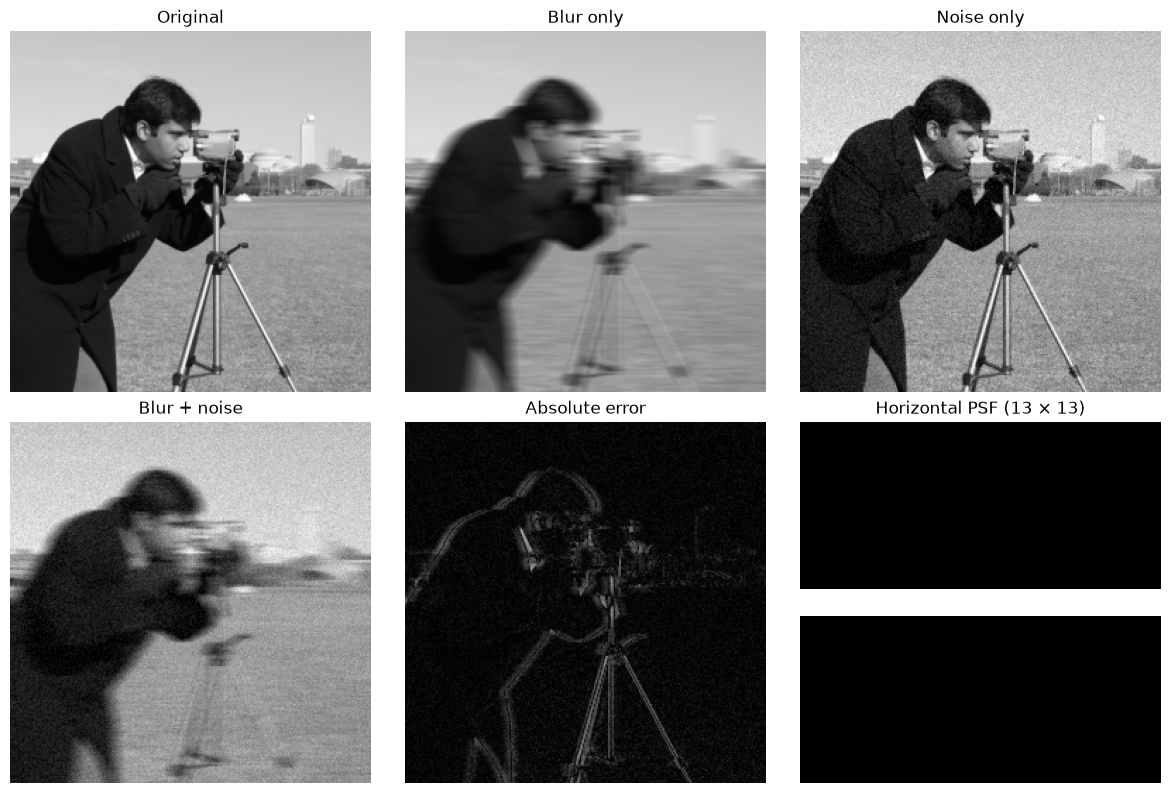

In [4]:
# EXPERIMENT 1: FORWARD DEGRADATION MODEL
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, transform
from scipy import ndimage as ndi

rng = np.random.default_rng(42)
original = transform.resize(data.camera(), (256, 256), anti_aliasing=True)

# Horizontal motion-blur PSF
psf = np.zeros((13, 13), dtype=float)
psf[6, :] = 1 / 13

blurred = ndi.convolve(original, psf, mode="reflect")
noise = rng.normal(0, 0.035, original.shape)
degraded = np.clip(blurred + noise, 0, 1)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
items = [(original, "Original"), (blurred, "Blur only"),
         (np.clip(original + noise, 0, 1), "Noise only"),
         (degraded, "Blur + noise"), (np.abs(original - degraded), "Absolute error")]

for ax, (im, title) in zip(axes.flat, items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title); ax.axis("off")

axes.flat[5].imshow(psf, cmap="gray", vmin=0, vmax=psf.max(), interpolation="nearest")
axes.flat[5].set_title("Horizontal PSF (13 × 13)")
axes.flat[5].axis("off")

plt.tight_layout()
plt.show()

## Noise characterization and spatial restoration

### Noise models
Noise is a random disturbance. The appropriate restoration method depends on its statistics and how it enters the image formation process.

- **Gaussian:** $n\sim\mathcal N(\mu,\sigma^2)$, often used as an approximation to sensor/readout noise.
- **Salt-and-pepper (impulse):** randomly selected pixels are replaced by extreme values, commonly 0 or 1.
- **Uniform:** $n\sim\mathcal U(a,b)$, with equal probability density within the specified interval.
- **Rayleigh:** nonnegative skewed noise with density $p(z)=\frac{z}{s^2}e^{-z^2/(2s^2)}$ for $z\geq0$ (zero-location parameterization).
- **Gamma/Erlang:** nonnegative skewed noise; Erlang is the integer-shape Gamma special case.
- **Exponential:** Gamma distribution with shape 1.

### Experiment 2 — Generate and compare noise distributions
**Tasks:** Simulate six distributions, visualize their effect on the same image, and inspect sampled noise histograms.  
**Question:** Can the distribution of noise be reliably identified from the histogram of the entire noisy image?

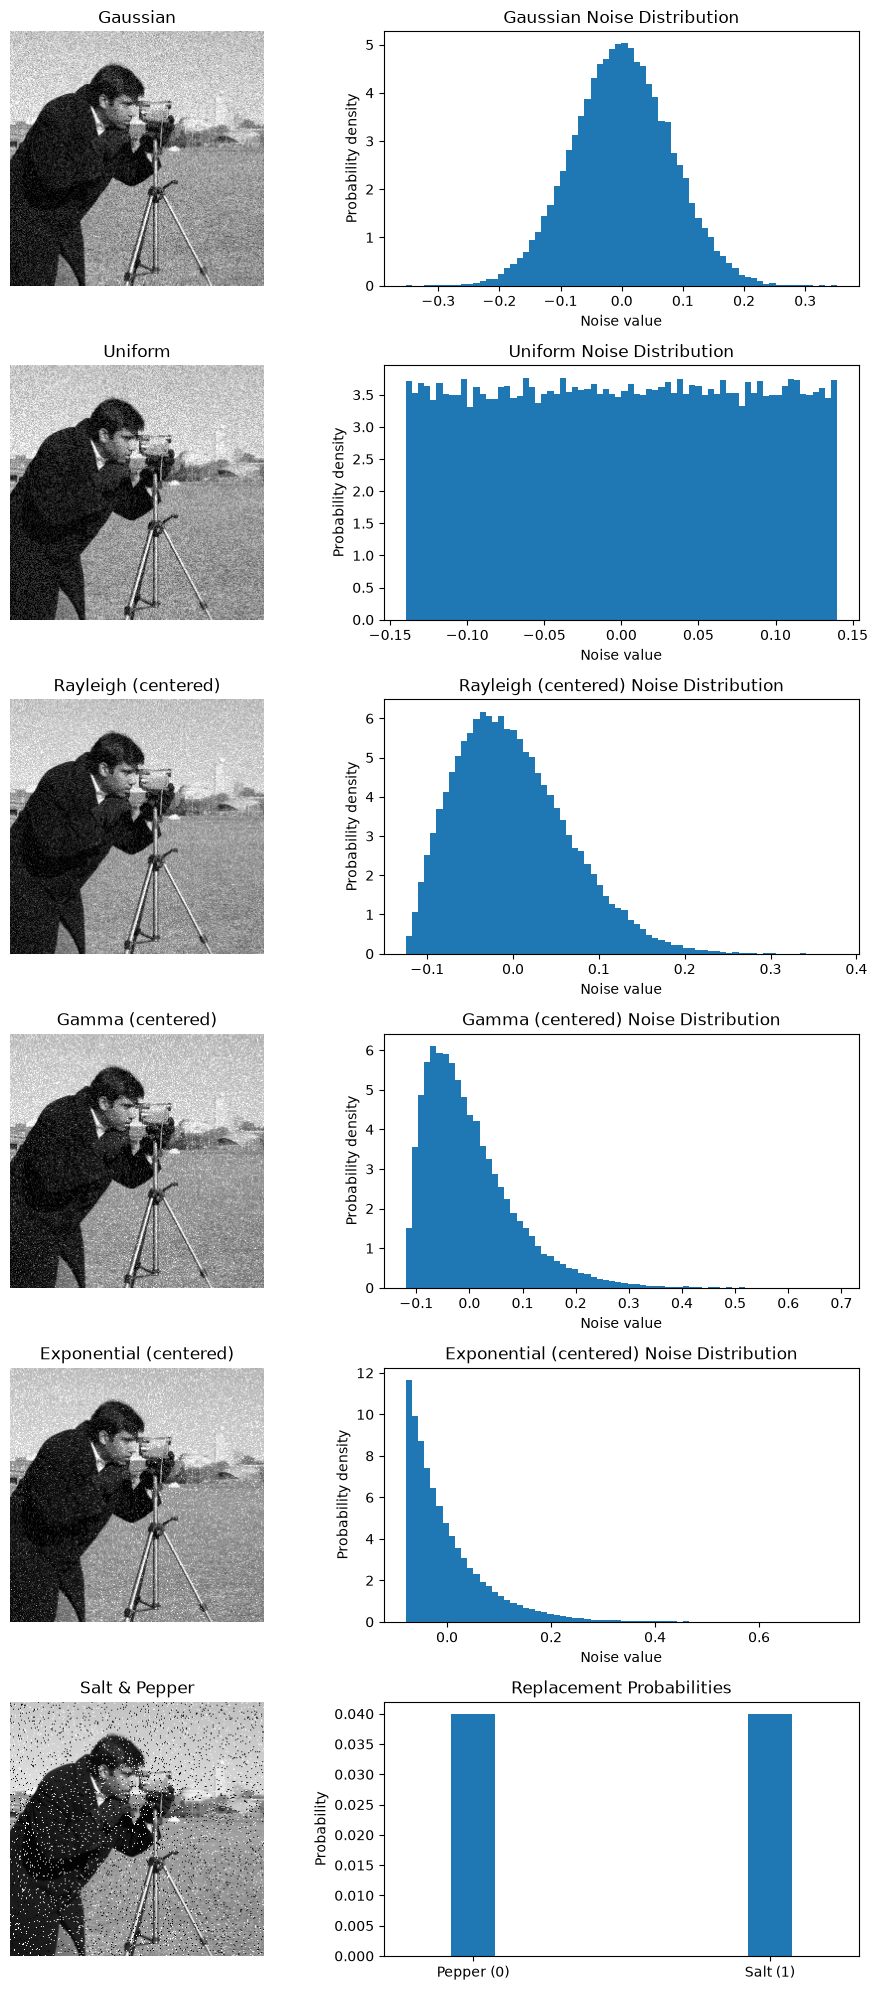

In [6]:
# EXPERIMENT 2: SIX NOISE DISTRIBUTIONS
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(123)
shape = original.shape

noise_fields = {
    "Gaussian": rng.normal(0, .08, shape),
    "Uniform": rng.uniform(-.14, .14, shape),
    "Rayleigh (centered)": (lambda a: a-a.mean())(rng.rayleigh(.10, shape)),
    "Gamma (centered)": (lambda a: a-a.mean())(rng.gamma(2., .06, shape)),
    "Exponential (centered)": (lambda a: a-a.mean())(rng.exponential(.08, shape)),
}

impulse = original.copy()
mask = rng.random(shape)
impulse[mask < .04] = 0
impulse[(mask >= .04) & (mask < .08)] = 1

fig, axes = plt.subplots(6, 2, figsize=(10, 20))

for i, (name, field) in enumerate(noise_fields.items()):
    axes[i, 0].imshow(np.clip(original + field, 0, 1),
                      cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(name)
    axes[i, 0].axis("off")

    axes[i, 1].hist(field.ravel(), bins=70, density=True)
    axes[i, 1].set_title(f"{name} Noise Distribution")
    axes[i, 1].set_xlabel("Noise value")
    axes[i, 1].set_ylabel("Probability density")

axes[5, 0].imshow(impulse, cmap="gray", vmin=0, vmax=1)
axes[5, 0].set_title("Salt & Pepper")
axes[5, 0].axis("off")

axes[5, 1].bar([0, 1], [.04, .04], width=.15)
axes[5, 1].set_xlim(-.3, 1.3)
axes[5, 1].set_xticks([0, 1], ["Pepper (0)", "Salt (1)"])
axes[5, 1].set_title("Replacement Probabilities")
axes[5, 1].set_ylabel("Probability")

plt.tight_layout()
plt.show()

### Noise estimation from homogeneous regions
A global image histogram mixes variations caused by actual scene content with variations caused by noise. A relatively uniform patch provides a better opportunity to estimate noise statistics. If the true patch is constant, its observed variance approximates the noise variance. If the patch has a gradient or texture, the estimate is biased upward.

### Experiment 3 — Estimate noise statistics
**Tasks:** Compare the global histogram with the histogram of a known homogeneous synthetic patch; estimate mean and standard deviation.  
**Question:** What happens if the selected patch contains an edge?

Estimated noise mean: -0.0003
Estimated noise std:  0.0595


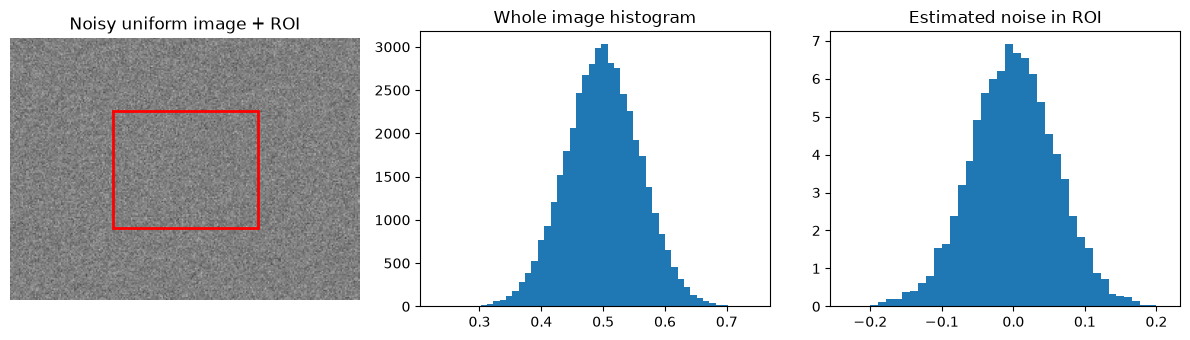

In [7]:
# EXPERIMENT 3: NOISE ESTIMATION FROM A HOMOGENEOUS PATCH
rng = np.random.default_rng(7)
flat = np.full((180, 240), .5)
flat_noisy = np.clip(flat + rng.normal(0, .06, flat.shape), 0, 1)
patch = flat_noisy[50:130, 70:170]
print(f"Estimated noise mean: {(patch-.5).mean():.4f}")
print(f"Estimated noise std:  {(patch-.5).std(ddof=1):.4f}")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].imshow(flat_noisy, cmap="gray", vmin=0, vmax=1)
axes[0].add_patch(plt.Rectangle((70, 50), 100, 80, fill=False, ec="red", lw=2))
axes[0].set_title("Noisy uniform image + ROI"); axes[0].axis("off")
axes[1].hist(flat_noisy.ravel(), bins=50); axes[1].set_title("Whole image histogram")
axes[2].hist((patch-.5).ravel(), bins=40, density=True)
axes[2].set_title("Estimated noise in ROI")
plt.tight_layout(); plt.show()

### Mean filters: arithmetic, geometric, harmonic, contraharmonic
For a local neighborhood $W$ containing $m n$ pixels, the **arithmetic mean** is

$$\hat f=\frac{1}{mn}\sum_{(r,c)\in W}g(r,c).$$

The **geometric mean** and **harmonic mean** are

$$\hat f_{geo}=\left(\prod_{W}g(r,c)\right)^{1/(mn)},\qquad
\hat f_{harm}=\frac{mn}{\sum_W 1/g(r,c)}.$$

The **contraharmonic mean** of order $Q$ is

$$\hat f_Q=\frac{\sum_W g(r,c)^{Q+1}}{\sum_W g(r,c)^Q}.$$

Positive $Q$ is used to suppress **pepper** noise, while negative $Q$ is used to suppress **salt** noise. A single contraharmonic filter generally cannot remove both simultaneously. Geometric and harmonic means require special care with zero-valued pixels; for clarity, this exercise uses small positive numerical safeguards.

### Experiment 4 — Compare mean-based restoration filters
**Tasks:** Restore a Gaussian-noisy image; compare mean filter sizes; compare the sign of $Q$ on salt-only and pepper-only images.  
**Question:** Why does the contraharmonic filter fail when the order has the wrong sign?

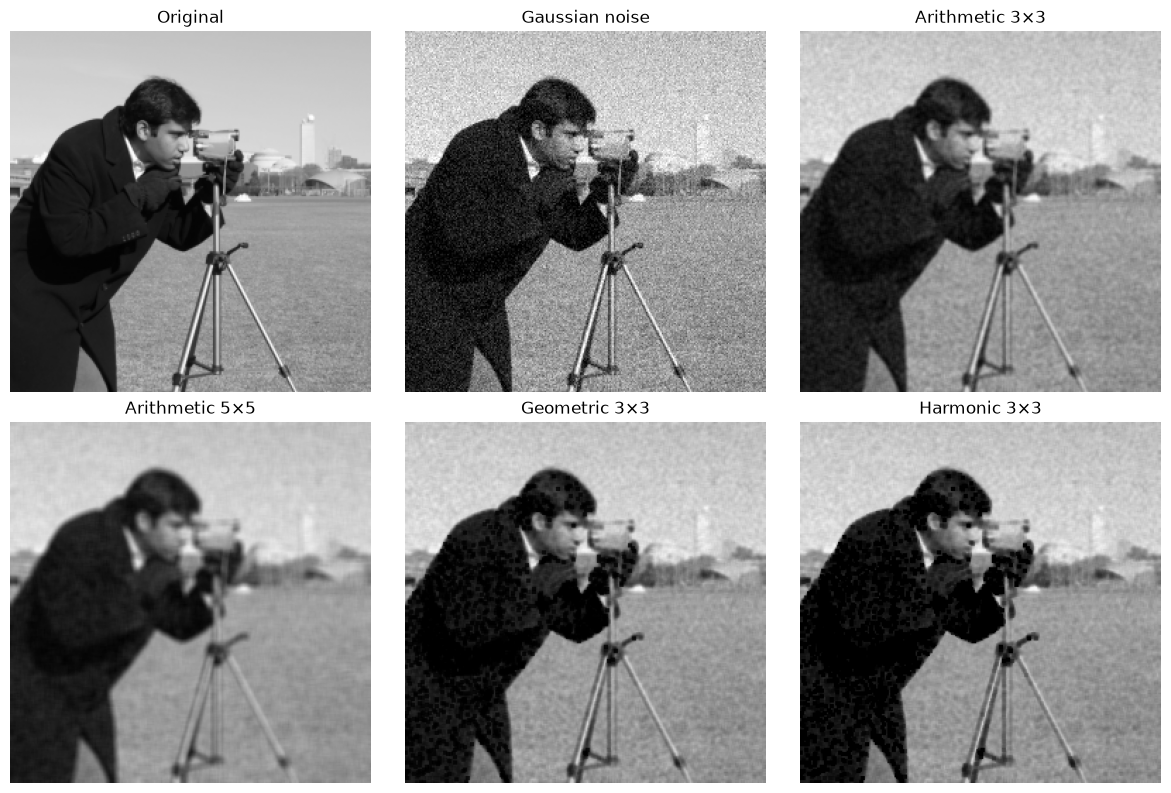

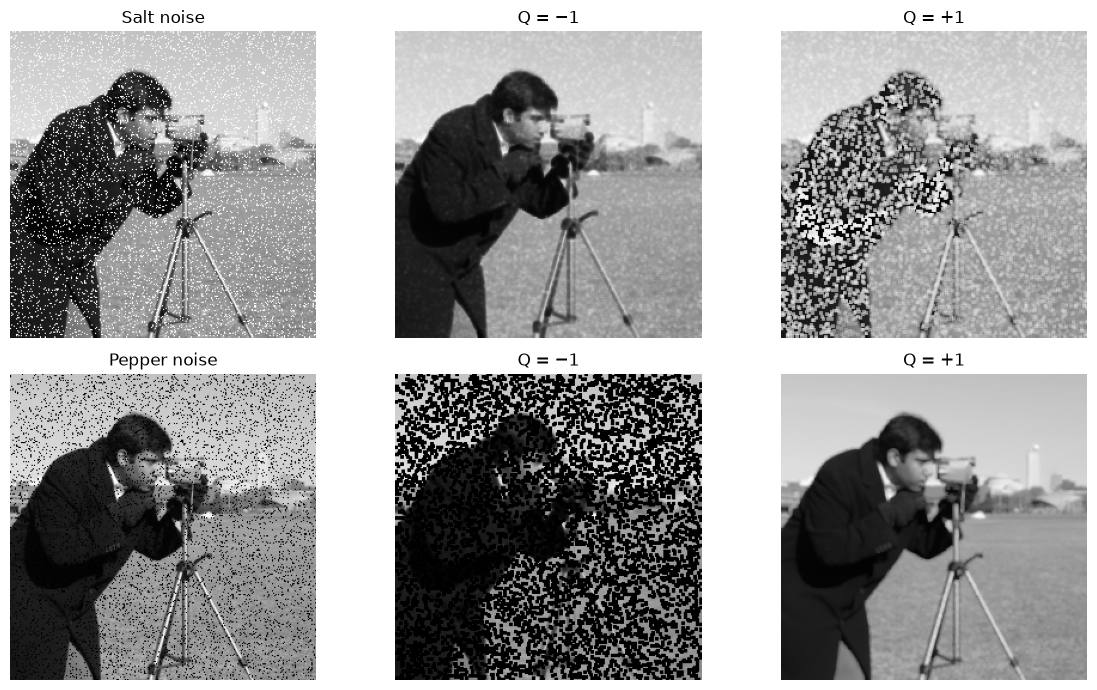

In [8]:
# EXPERIMENT 4: MEAN-BASED RESTORATION
from scipy.ndimage import uniform_filter
rng = np.random.default_rng(8)
g = np.clip(original + rng.normal(0, .07, original.shape), 0, 1)
eps = 1e-6

def geometric_mean(image, size=3):
    return np.exp(uniform_filter(np.log(np.maximum(image, eps)), size=size))

def harmonic_mean(image, size=3):
    return 1 / uniform_filter(1 / np.maximum(image, eps), size=size)

def contraharmonic(image, Q, size=3):
    z = np.maximum(image, eps)
    num = uniform_filter(z ** (Q + 1), size=size)
    den = uniform_filter(z ** Q, size=size)
    return np.clip(num / np.maximum(den, eps), 0, 1)

results = [(original, "Original"), (g, "Gaussian noise"),
           (uniform_filter(g, 3), "Arithmetic 3×3"),
           (uniform_filter(g, 5), "Arithmetic 5×5"),
           (geometric_mean(g), "Geometric 3×3"),
           (harmonic_mean(g), "Harmonic 3×3")]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (im, title) in zip(axes.flat, results):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

salt = original.copy(); pepper = original.copy()
salt[rng.random(original.shape) < .10] = 1
pepper[rng.random(original.shape) < .10] = 0
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for row, (noisy, name) in enumerate([(salt, "Salt"), (pepper, "Pepper")]):
    for ax, (im, title) in zip(axes[row], [
        (noisy, name + " noise"),
        (contraharmonic(noisy, -1), "Q = −1"),
        (contraharmonic(noisy, 1), "Q = +1")]):
        ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

### Order-statistic filters
Rank filters sort pixel intensities in a local neighborhood. The **median** replaces the center pixel with the middle ranked value and is often effective against salt-and-pepper noise. The **minimum** suppresses bright impulses; the **maximum** suppresses dark impulses. The **midpoint** averages the neighborhood minimum and maximum. The **alpha-trimmed mean** discards $D$ lowest and $D$ highest observations before averaging:

$$\hat f=\frac{1}{mn-2D}\sum_{k=D+1}^{mn-D}g_{(k)},$$

where $g_{(k)}$ are sorted neighborhood intensities. $D=0$ gives the arithmetic mean; the largest permissible $D$ for an odd neighborhood yields the median.

### Experiment 5 — Compare rank filters
**Tasks:** Apply median, min, max, midpoint, and alpha-trimmed filters to impulse noise.  
**Question:** Why does the midpoint filter perform poorly for bipolar impulse noise?

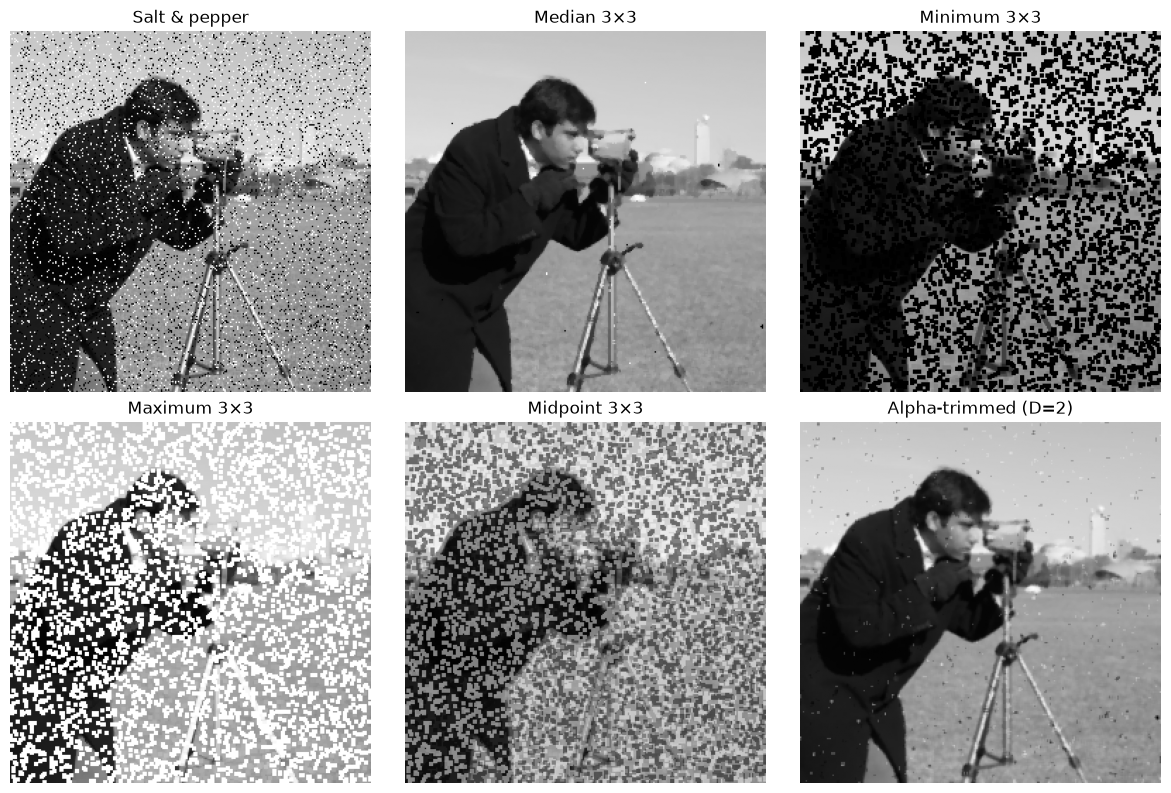

In [9]:
# EXPERIMENT 5: ORDER-STATISTIC FILTERS
from scipy.ndimage import median_filter, minimum_filter, maximum_filter, generic_filter
rng = np.random.default_rng(9)
sp = original.copy()
u = rng.random(original.shape)
sp[u < .06] = 0
sp[(u >= .06) & (u < .12)] = 1

def alpha_trimmed(values, D=2):
    v = np.sort(values)
    return v[D:len(v)-D].mean() if D else v.mean()

minimum = minimum_filter(sp, size=3)
maximum = maximum_filter(sp, size=3)
rank_results = [(sp, "Salt & pepper"),
                (median_filter(sp, 3), "Median 3×3"),
                (minimum, "Minimum 3×3"),
                (maximum, "Maximum 3×3"),
                ((minimum + maximum) / 2, "Midpoint 3×3"),
                (generic_filter(sp, alpha_trimmed, size=3, extra_keywords={"D": 2}),
                 "Alpha-trimmed (D=2)")]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (im, title) in zip(axes.flat, rank_results):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

### Adaptive local-statistics filtering
A fixed filter uses the same rule everywhere. An **adaptive** filter adjusts its response using local image statistics. For an additive zero-mean noise model with variance $\sigma_n^2$, one common local-statistics estimator is

$$\hat f(x,y)=\mu_L+\max\left(0,1-\frac{\sigma_n^2}{\sigma_L^2}\right)(g(x,y)-\mu_L),$$

where $\mu_L$ and $\sigma_L^2$ are the local mean and variance. When local variation is mostly explained by noise, the output approaches the local mean; where local signal variation dominates, it retains more of the observed pixel. This is a simplified adaptive local-noise-reduction demonstration, not a universal model of all noise types.

### Experiment 6 — Adaptive versus fixed smoothing
**Tasks:** Compare a fixed mean filter and a local-statistics filter under Gaussian noise.  
**Question:** Which method better preserves high-contrast boundaries, and why?

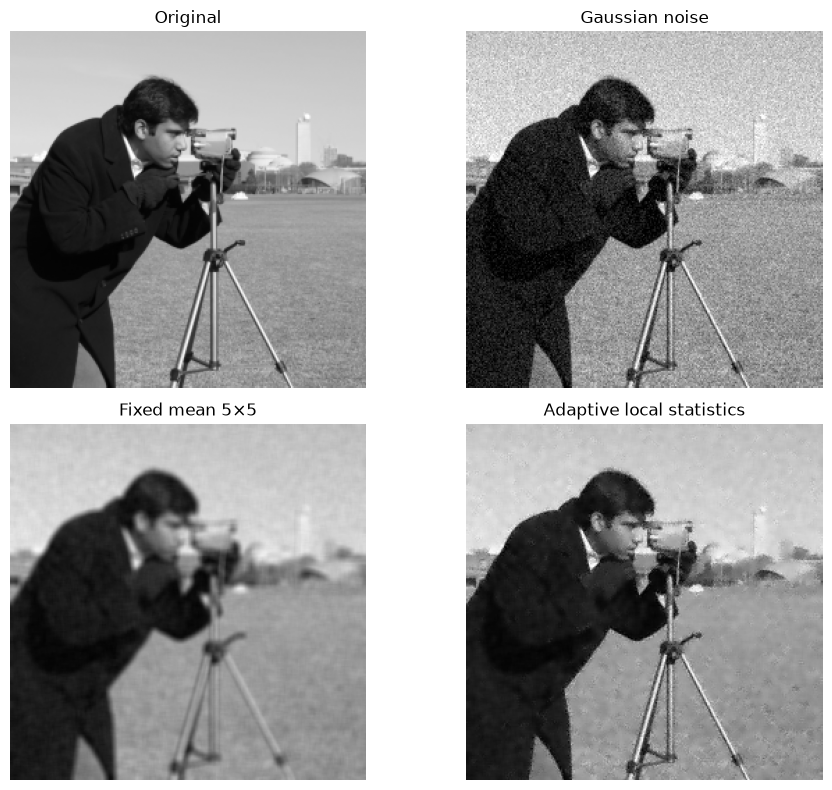

In [10]:
# EXPERIMENT 6: ADAPTIVE LOCAL NOISE REDUCTION
rng = np.random.default_rng(10)
sigma = .06
noisy = np.clip(original + rng.normal(0, sigma, original.shape), 0, 1)
local_mean = uniform_filter(noisy, size=5, mode="reflect")
local_var = np.maximum(uniform_filter(noisy**2, size=5, mode="reflect") - local_mean**2, 0)
weight = np.maximum(0, 1 - sigma**2 / np.maximum(local_var, 1e-9))
adaptive = np.clip(local_mean + weight * (noisy - local_mean), 0, 1)
fixed = uniform_filter(noisy, size=5, mode="reflect")
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (im, title) in zip(axes.flat, [(original, "Original"), (noisy, "Gaussian noise"),
                                      (fixed, "Fixed mean 5×5"), (adaptive, "Adaptive local statistics")]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

## Frequency-domain restoration

### Periodic interference
Periodic noise often appears as structured lines or ripples. A sinusoidal disturbance in the spatial domain produces a pair of symmetric peaks in the centered Fourier magnitude spectrum (for a real-valued image). **Bandreject filters** attenuate a ring of frequencies; **bandpass filters** retain a ring. **Notch reject filters** suppress small neighborhoods around selected interference frequencies, typically in symmetric pairs.

A simple ideal notch reject filter equals zero inside disks centered at $(\pm u_0,\pm v_0)$ relative to the shifted Fourier origin and one elsewhere. Sharp cutoffs can introduce ringing; smoother notches reduce abrupt spectral transitions.

### Experiment 7 — Remove periodic interference with notch filtering
**Tasks:** Introduce a known sinusoidal disturbance, inspect the FFT, build symmetric notch masks, and restore the image.  
**Question:** Why must the notch locations occur in conjugate-symmetric pairs?

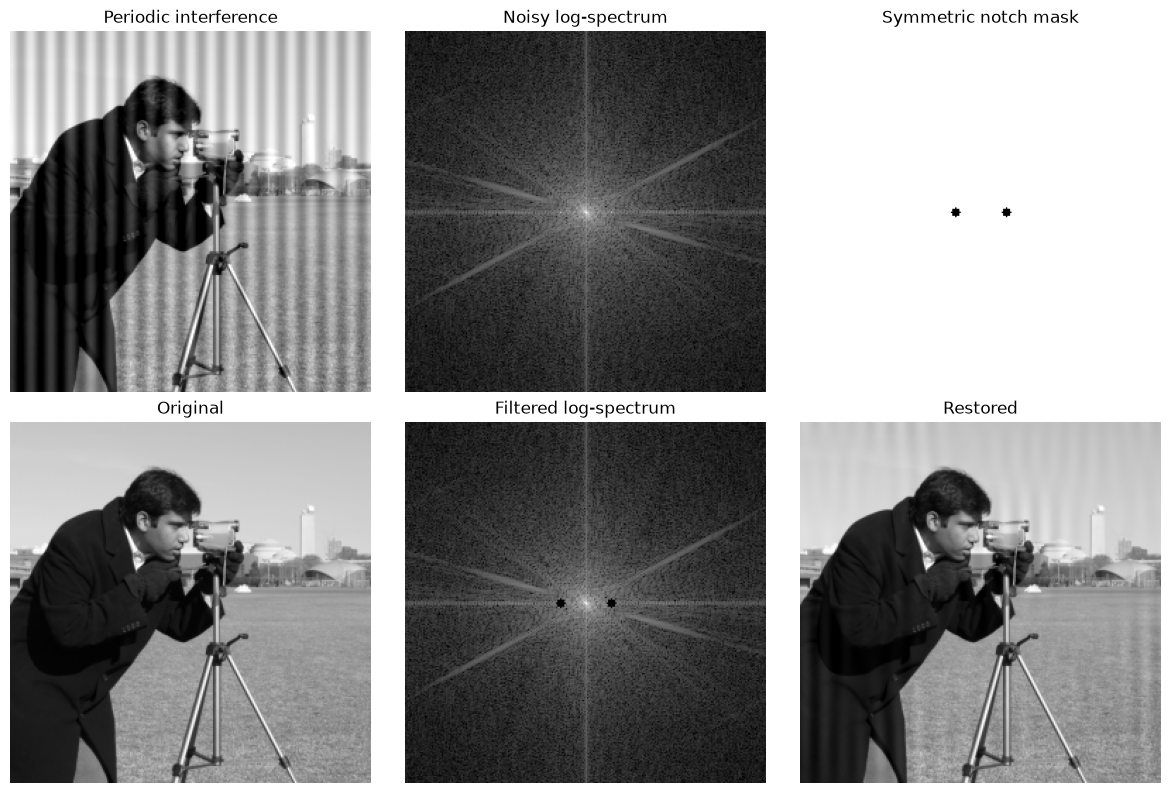

In [11]:
# EXPERIMENT 7: PERIODIC NOISE AND NOTCH FILTERING
M, N = original.shape
Y, X = np.indices((M, N))
# Spatial sinusoid at horizontal frequency ±18 cycles/image
periodic = .12 * np.cos(2*np.pi*18*X/N)
noisy_periodic = original + periodic  # Do not clip before FFT: preserve the linear model
F = np.fft.fftshift(np.fft.fft2(noisy_periodic))
cy, cx = M//2, N//2
notch = np.ones((M, N), dtype=float)
for dx in [-18, 18]:
    D2 = (Y-cy)**2 + (X-(cx+dx))**2
    notch[D2 <= 3**2] = 0
restored = np.fft.ifft2(np.fft.ifftshift(F*notch)).real
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
items = [(noisy_periodic, "Periodic interference", "image"),
         (np.log1p(np.abs(F)), "Noisy log-spectrum", "spectrum"),
         (notch, "Symmetric notch mask", "mask"),
         (original, "Original", "image"),
         (np.log1p(np.abs(F*notch)), "Filtered log-spectrum", "spectrum"),
         (restored, "Restored", "image")]
for ax, (im, title, kind) in zip(axes.flat, items):
    if kind == "image": ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    elif kind == "mask": ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    else: ax.imshow(im, cmap="gray")
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

## Deblurring: inverse and Wiener filters

### The inverse filter
In the absence of noise, $G=FH$, suggesting $\hat F=G/H$. But if $|H|$ is very small, the division amplifies measurement noise dramatically. An **inverse filter with a threshold** avoids division where $|H|$ is too small; this trades recovery of attenuated frequencies for numerical stability.

For a demonstration with a known PSF, we use circular convolution in the Fourier domain so that the simulated forward model and the inverse model match exactly. This is an educational simplification; real camera boundaries generally do not wrap around.

### Experiment 8 — Inverse filtering and instability
**Tasks:** Construct a Gaussian PSF, blur an image, add weak noise, and compare constrained inverse thresholds.  
**Question:** Why can a smaller inverse threshold produce a worse reconstruction?

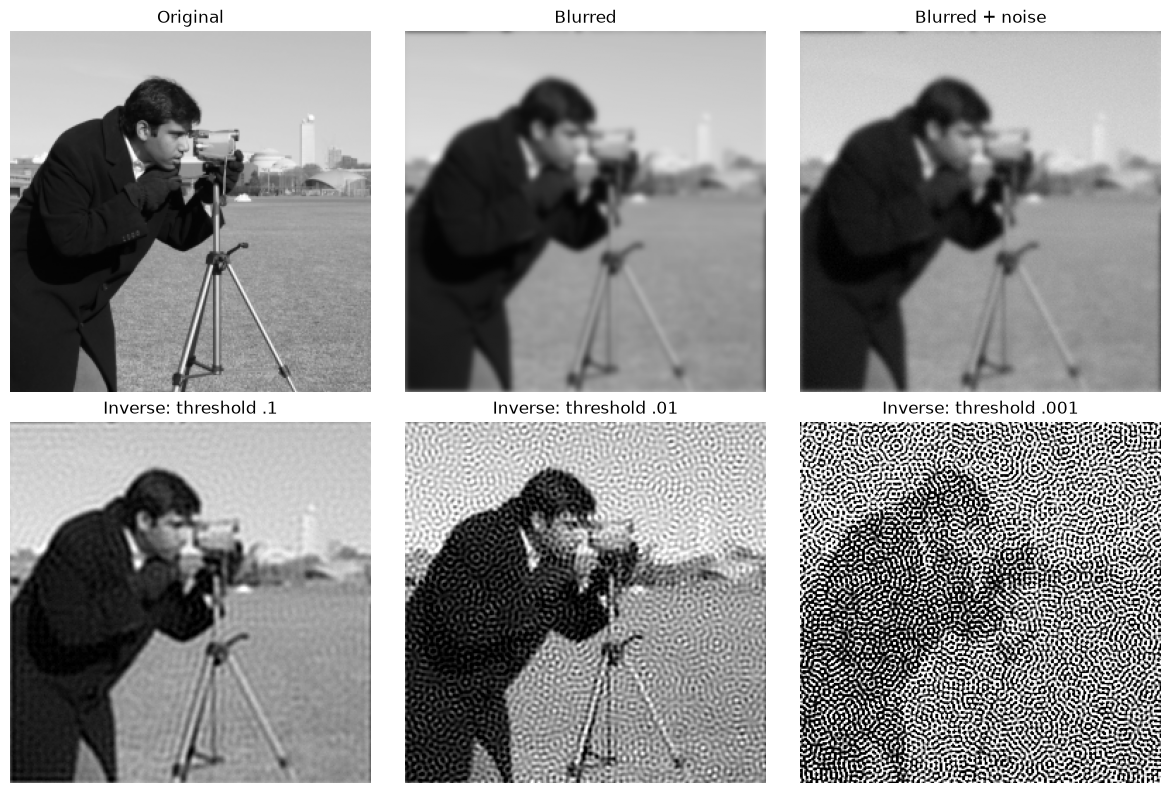

In [12]:
# EXPERIMENT 8: CONSTRAINED INVERSE FILTERING
from scipy.ndimage import gaussian_filter
rng = np.random.default_rng(11)
# Fourier transfer function of a circular Gaussian blur
sigma_blur = 2.0
psf_spatial = np.zeros_like(original)
psf_spatial[0, 0] = 1
psf_spatial = gaussian_filter(psf_spatial, sigma_blur, mode="wrap")
H = np.fft.fft2(psf_spatial)
F_true = np.fft.fft2(original)
blurred_circular = np.fft.ifft2(F_true * H).real
observation = blurred_circular + rng.normal(0, .008, original.shape)
G = np.fft.fft2(observation)

def constrained_inverse(G, H, threshold):
    F_est = G.copy()
    valid = np.abs(H) >= threshold
    F_est[valid] = G[valid] / H[valid]
    return np.fft.ifft2(F_est).real

inv_01 = constrained_inverse(G, H, .1)
inv_001 = constrained_inverse(G, H, .01)
inv_0001 = constrained_inverse(G, H, .001)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
items = [(original, "Original"), (blurred_circular, "Blurred"),
         (observation, "Blurred + noise"),
         (inv_01, "Inverse: threshold .1"),
         (inv_001, "Inverse: threshold .01"),
         (inv_0001, "Inverse: threshold .001")]
for ax, (im, title) in zip(axes.flat, items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

### Wiener filtering and regularization
The Wiener filter addresses the noise amplification of naive inversion by balancing deblurring against noise suppression. Under a simplified constant noise-to-signal power ratio approximation $K$,

$$\hat F(u,v)=\frac{H^*(u,v)}{|H(u,v)|^2+K}\,G(u,v).$$

$H^*$ denotes complex conjugation. For $K>0$, the denominator does not vanish, preventing unbounded amplification. Larger $K$ generally favors noise suppression but may leave more residual blur. The ideal Wiener filter uses frequency-dependent signal and noise power spectra; the constant-$K$ form here is a common approximation.

### Experiment 9 — Wiener restoration and parameter sensitivity
**Tasks:** Compare several $K$ values against inverse filtering on the same degraded image.  
**Question:** Why does the visually sharpest result not always have the smallest reconstruction error?

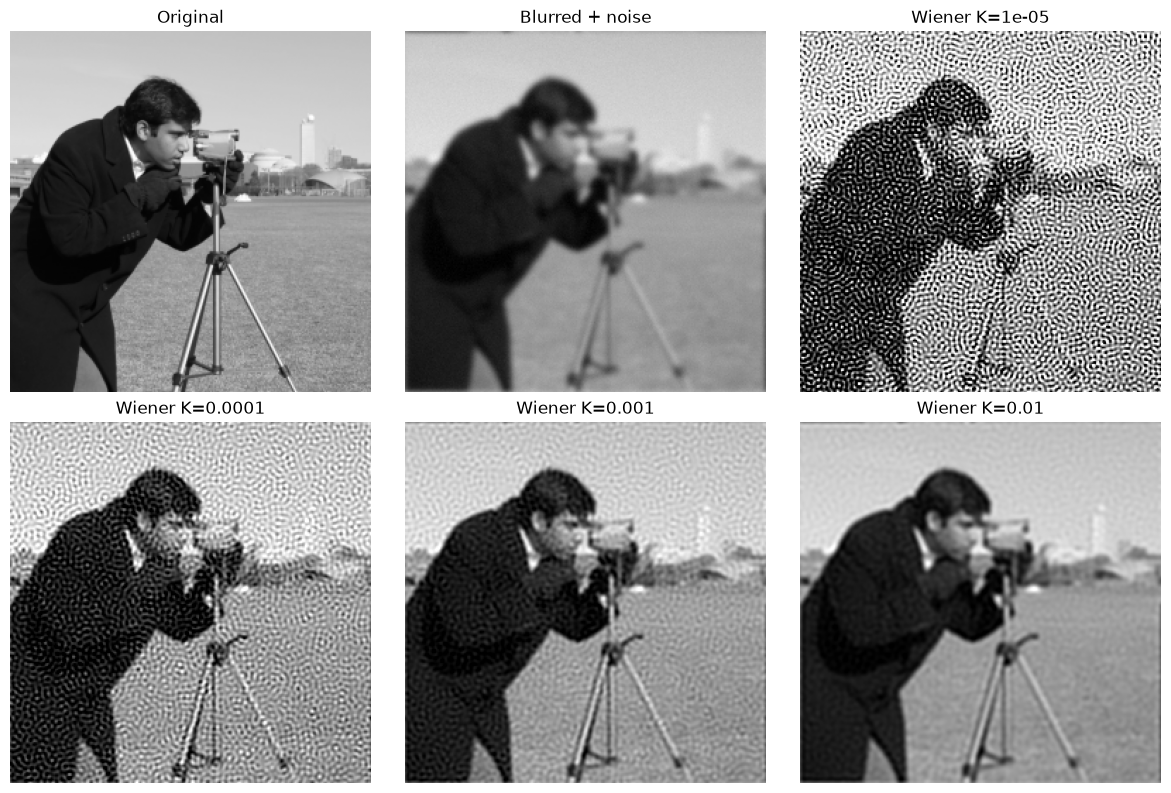

In [13]:
# EXPERIMENT 9: WIENER FILTERING

def wiener_restore(G, H, K):
    F_est = np.conj(H) * G / (np.abs(H)**2 + K)
    return np.fft.ifft2(F_est).real

Ks = [1e-5, 1e-4, 1e-3, 1e-2]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
items = [(original, "Original"), (observation, "Blurred + noise")]
items += [(wiener_restore(G, H, k), f"Wiener K={k:g}") for k in Ks]
for ax, (im, title) in zip(axes.flat, items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

## Quantitative assessment (supplementary)

Visual comparison is useful but subjective. When the reference image is available (as in these controlled simulations), compare restorations using:

- **Mean squared error (MSE):** $\mathrm{MSE}=\frac{1}{MN}\sum_{x,y}(f(x,y)-\hat f(x,y))^2$.
- **Peak signal-to-noise ratio (PSNR):** $\mathrm{PSNR}=10\log_{10}(L^2/\mathrm{MSE})$ dB, with intensity range $L=1$ here.
- **Structural similarity (SSIM):** a local measure of luminance, contrast, and structural agreement.

Higher PSNR and SSIM usually indicate closer agreement with the reference, but they do not guarantee perceptual or downstream-task superiority. Clipping should be applied consistently for image-domain comparisons.

### Experiment 10 — Compare restoration quality
**Tasks:** Compute MSE, PSNR, and SSIM for the degraded observation, constrained inverse restoration, and several Wiener parameters.  
**Question:** Does the best $K$ depend on the noise level and PSF?

In [14]:
# EXPERIMENT 10: QUANTITATIVE RESTORATION ASSESSMENT
from skimage.metrics import mean_squared_error, peak_signal_noise_ratio, structural_similarity

candidates = {"Degraded": observation,
              "Inverse (T=.01)": inv_001,
              **{f"Wiener K={k:g}": wiener_restore(G, H, k) for k in Ks}}

print(f"{'Method':<22} {'MSE':>12} {'PSNR (dB)':>12} {'SSIM':>10}")
print("-" * 60)
for name, estimate in candidates.items():
    estimate = np.clip(estimate, 0, 1)
    mse = mean_squared_error(original, estimate)
    psnr = peak_signal_noise_ratio(original, estimate, data_range=1)
    ssim = structural_similarity(original, estimate, data_range=1)
    print(f"{name:<22} {mse:>12.6f} {psnr:>12.2f} {ssim:>10.4f}")

Method                          MSE    PSNR (dB)       SSIM
------------------------------------------------------------
Degraded                   0.003628        24.40     0.7245
Inverse (T=.01)            0.012554        19.01     0.2446
Wiener K=1e-05             0.080118        10.96     0.0783
Wiener K=0.0001            0.012416        19.06     0.2414
Wiener K=0.001             0.002625        25.81     0.5531
Wiener K=0.01              0.002087        26.81     0.7771
